In [2]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [3]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

#mystery_flower = [4.5, 1]
#mystery_flower = [1.5, 0.8]   # on changing mystery_flower values we will see the predict  what the new myster flower cooordinate belongs to (in class activity)
mystery_flower = [5, 1.5]

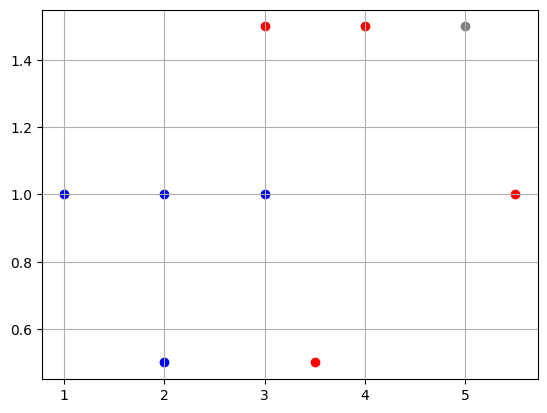

In [4]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [5]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [6]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

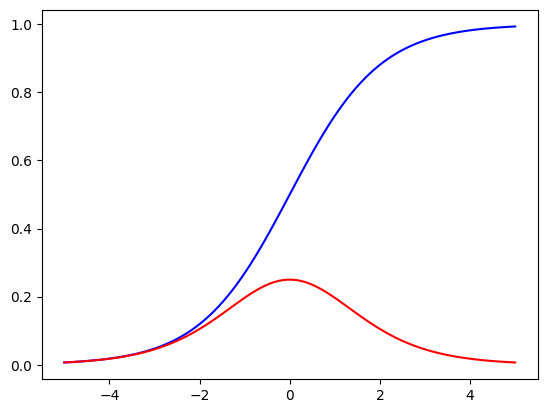

In [7]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

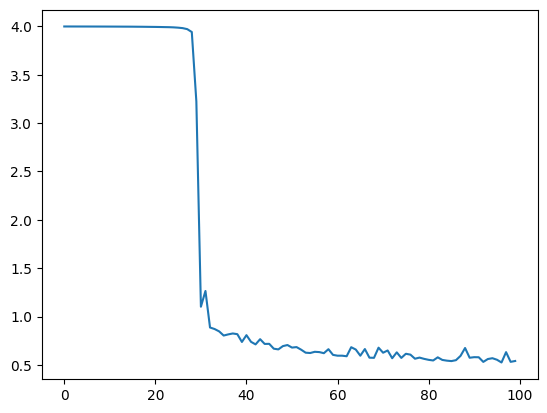

In [8]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

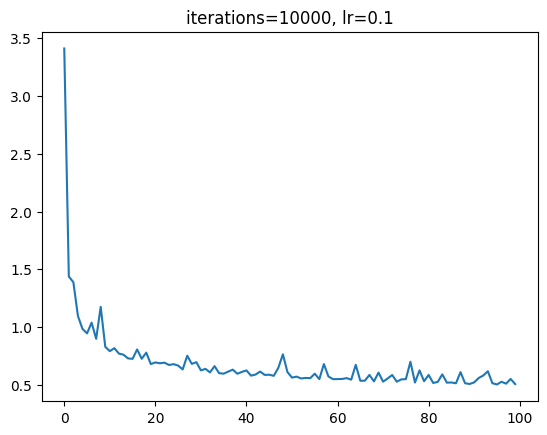

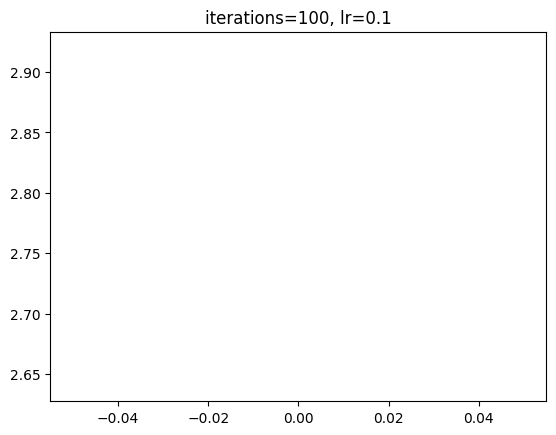

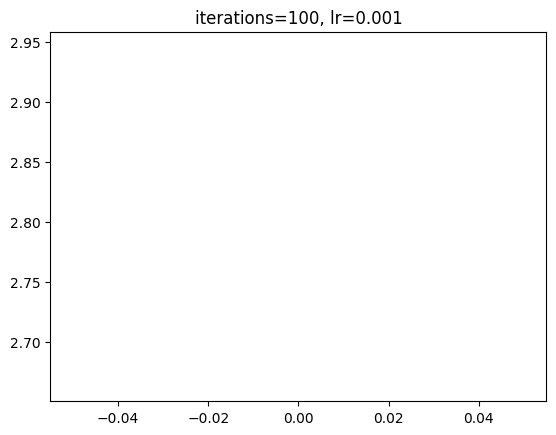

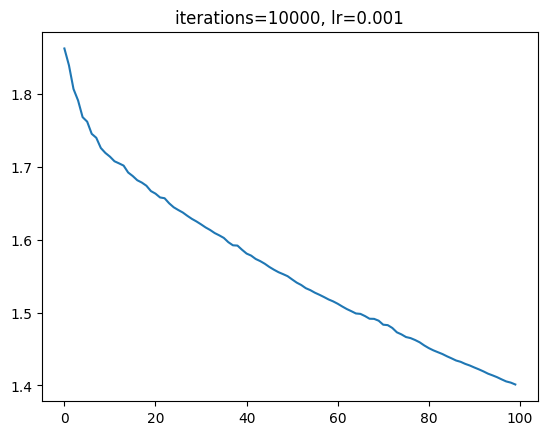

CPU times: user 451 ms, sys: 5.12 ms, total: 457 ms
Wall time: 455 ms


In [9]:
%%time

# train Changing lr and iterations value (in class activity)
import time

def train_run2(iterations, learning_rate): # we will change iterations and lr value
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    #iterations = 100
    #learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

# CHANGE 4: loop over every combination as mentioned
itlr = [(10000, 0.1), (100, 0.1), (100, 0.001), (10000, 0.001)]

for it, lr in itlr:
    start = time.time()
    costs, w1, w2, b = train_run2(it, lr)
    fig = plt.plot(costs)
    plt.title(f"iterations={it}, lr={lr}")
    plt.show()

In [10]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.7569402171054986
close to 0 -> blue, close to 1 -> red


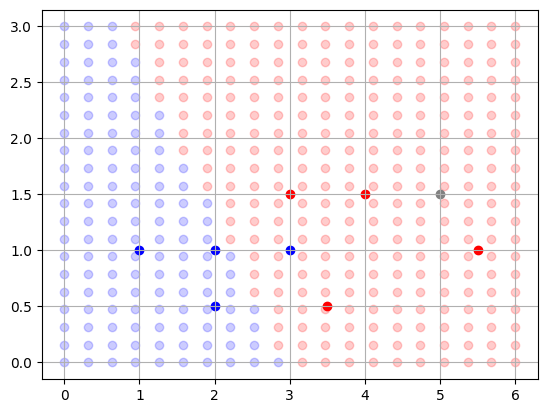

In [11]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

In [12]:
# Part 2 – One-hot vectors: In class activity
S1 = "New York Times"
S2 = "Los Angeles Times"
S3 = "Los Angeles York"

V = ['New', 'York', 'Times', 'Los', 'Angeles']   # vocabulary, 5 unique words
print(len(V))

# Sentence vectors (1 = word present, 0 = absent) Applying One hot encoding to the sentences
# S1= [1 1 1 0 0]
# S2= [0 0 1 1 1]
# S3= [0 1 0 1 1]

def sentence_vector(sentence):
    words = sentence.split()
    return [1 if w in words else 0 for w in V]

s1 = sentence_vector(S1)
s2 = sentence_vector(S2)
s3 = sentence_vector(S3)

print("S1:", s1)   # expected [1, 1, 1, 0, 0]
print("S2:", s2)   # expected [0, 0, 1, 1, 1]
print("S3:", s3)   # expected [0, 1, 0, 1, 1]

# Layer 1 – lookup function h (h is a matrix of size 3×5)
# s=h*w

import numpy as np

h = np.array([s1, s2, s3])
print("h matrix")
print (h)
print("h shape:", h.shape)    # (3, 5)

# Layer 2 – S = h · W  (h: 3×5, W: 5×2, output S: 3×2)

W = np.random.randn(5, 2)     # 5 vocabulary words -> 2 output neurons, random values
S = np.dot(h, W)              # use np.dot

print("W shape:", W.shape)    # (5, 2)
print ("w",W)
print("Output matrix: S shape:", S.shape)    # (3, 2)
print(S)


5
S1: [1, 1, 1, 0, 0]
S2: [0, 0, 1, 1, 1]
S3: [0, 1, 0, 1, 1]
h matrix
[[1 1 1 0 0]
 [0 0 1 1 1]
 [0 1 0 1 1]]
h shape: (3, 5)
W shape: (5, 2)
w [[ 0.24405046 -0.68148009]
 [ 1.09528468  0.96895   ]
 [ 1.61127773 -0.07493519]
 [ 0.45271434 -0.35363936]
 [ 1.67539773 -1.50589915]]
Output matrix: S shape: (3, 2)
[[ 2.95061287  0.21253471]
 [ 3.7393898  -1.9344737 ]
 [ 3.22339675 -0.89058851]]
